In [14]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
df=pd.read_csv("train.csv")

In [2]:
df.head()

,PassengerId,HomePlanet,CryoSleep,Cabin,Destination,Age,VIP,RoomService,FoodCourt,ShoppingMall,Spa,VRDeck,Name,Transported
0,0001_01,Europa,False,B/0/P,TRAPPIST-1e,39.0,False,0.0,0.0,0.0,0.0,0.0,Maham Ofracculy,False
1,0002_01,Earth,False,F/0/S,TRAPPIST-1e,24.0,False,109.0,9.0,25.0,549.0,44.0,Juanna Vines,True
2,0003_01,Europa,False,A/0/S,TRAPPIST-1e,58.0,True,43.0,3576.0,0.0,6715.0,49.0,Altark Susent,False
3,0003_02,Europa,False,A/0/S,TRAPPIST-1e,33.0,False,0.0,1283.0,371.0,3329.0,193.0,Solam Susent,False
4,0004_01,Earth,False,F/1/S,TRAPPIST-1e,16.0,False,303.0,70.0,151.0,565.0,2.0,Willy Santantines,True


In [3]:
df.isna().sum()  

PassengerId       0
HomePlanet      201
CryoSleep       217
Cabin           199
Destination     182
Age             179
VIP             203
RoomService     181
FoodCourt       183
ShoppingMall    208
Spa             183
VRDeck          188
Name            200
Transported       0
dtype: int64

In [12]:
cat_features = ["HomePlanet", "CryoSleep", "Destination", "VIP"]
num_features = ["Age", "RoomService", "FoodCourt", "ShoppingMall", "Spa", "VRDeck"]

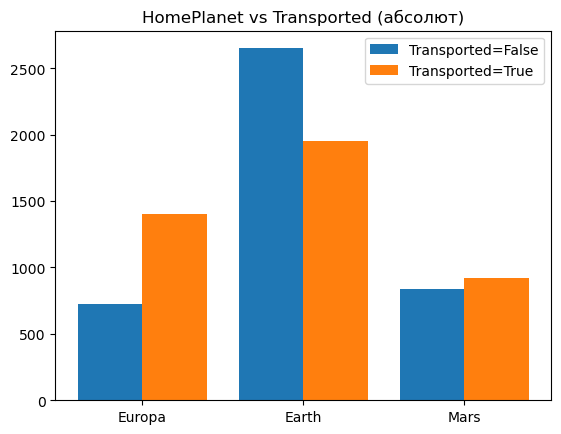

In [19]:
planets = df["HomePlanet"].dropna().unique()
x = np.arange(len(planets))
width = 0.4

for i, val in enumerate([False, True]):
    counts = [len(df[(df["HomePlanet"] == p) & (df["Transported"] == val)]) for p in planets]
    plt.bar(x + i * width, counts, width, label=f"Transported={val}")

plt.xticks(x + width / 2, planets)
plt.title("HomePlanet vs Transported (абсолют)")
plt.legend()
plt.show()
#Вывод: Планета влияет

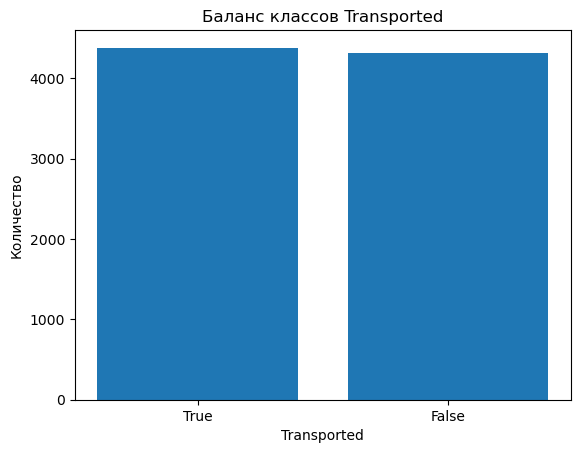

In [20]:
counts = df["Transported"].value_counts()
plt.bar(counts.index.astype(str), counts.values)
plt.title("Баланс классов Transported")
plt.xlabel("Transported")
plt.ylabel("Количество")
plt.show()

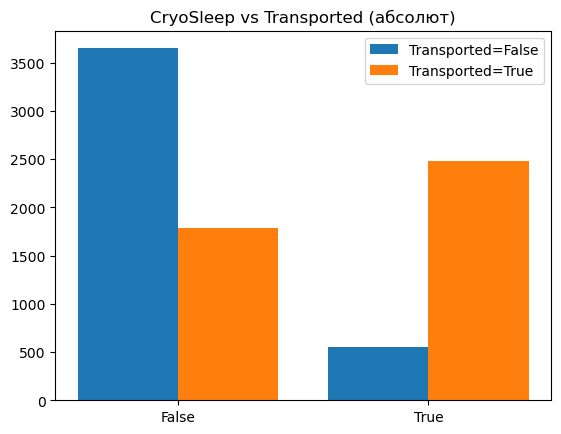

In [21]:
planets = df["CryoSleep"].dropna().unique()
x = np.arange(len(planets))
width = 0.4

for i, val in enumerate([False, True]):
    counts = [len(df[(df["CryoSleep"] == p) & (df["Transported"] == val)]) for p in planets]
    plt.bar(x + i * width, counts, width, label=f"Transported={val}")

plt.xticks(x + width / 2, planets)
plt.title("CryoSleep vs Transported (абсолют)")
plt.legend()
plt.show()
#Вывод: сон очень влияет

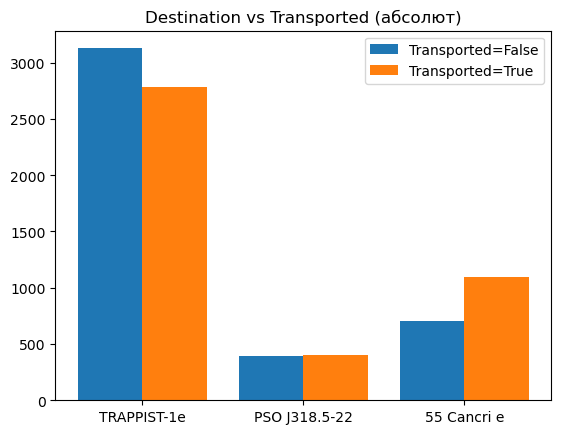

In [22]:
planets = df["Destination"].dropna().unique()
x = np.arange(len(planets))
width = 0.4

for i, val in enumerate([False, True]):
    counts = [len(df[(df["Destination"] == p) & (df["Transported"] == val)]) for p in planets]
    plt.bar(x + i * width, counts, width, label=f"Transported={val}")

plt.xticks(x + width / 2, planets)
plt.title("Destination vs Transported (абсолют)")
plt.legend()
plt.show()
#Вывод: почти не влияет

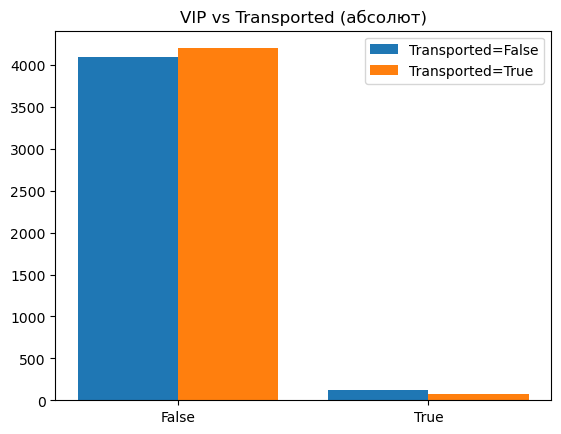

In [26]:
planets = df["VIP"].dropna().unique()
x = np.arange(len(planets))
width = 0.4

for i, val in enumerate([False, True]):
    counts = [len(df[(df["VIP"] == p) & (df["Transported"] == val)]) for p in planets]
    plt.bar(x + i * width, counts, width, label=f"Transported={val}")

plt.xticks(x + width / 2, planets)
plt.title("VIP vs Transported (абсолют)")
plt.legend()
plt.show()
#Вывод: Очень слабо влияет

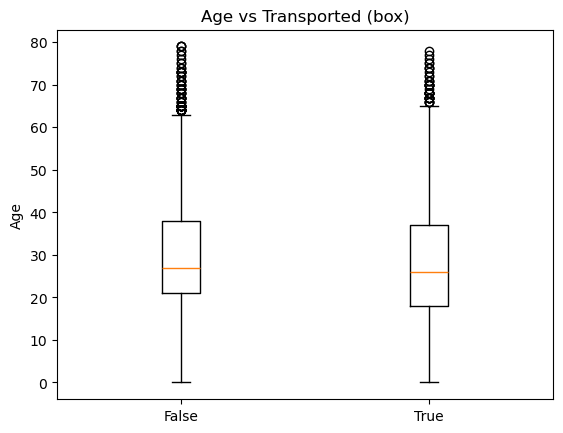

In [28]:
groups = [df[df["Transported"] == v]["Age"].dropna() for v in [False, True]]
plt.boxplot(groups, labels=["False", "True"])
plt.title("Age vs Transported (box)")
plt.ylabel("Age")
plt.show()